# UCI_Dry_Bean_Data

In [1]:
# step 1:import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# step 2:Load the dataset
df = pd.read_csv(r"C:\Users\asusvivobook\Desktop\FSDS\ML Practicals\UCI_Dry_Bean_Data\Dry_Bean_Dataset.csv")

In [3]:
# data exploration
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
# check the columns
df.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='str')

In [6]:
#check the shape
df.shape

(13611, 17)

In [7]:
# check the null and missing values
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [8]:
# check the duplicate values
df.duplicated().sum()

np.int64(68)

In [9]:
# describe the dataset
df.describe

<bound method NDFrame.describe of         Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0      28395    610.291       208.178117       173.888747      1.197191   
1      28734    638.018       200.524796       182.734419      1.097356   
2      29380    624.110       212.826130       175.931143      1.209713   
3      30008    645.884       210.557999       182.516516      1.153638   
4      30140    620.134       201.847882       190.279279      1.060798   
...      ...        ...              ...              ...           ...   
13606  42097    759.696       288.721612       185.944705      1.552728   
13607  42101    757.499       281.576392       190.713136      1.476439   
13608  42139    759.321       281.539928       191.187979      1.472582   
13609  42147    763.779       283.382636       190.275731      1.489326   
13610  42159    772.237       295.142741       182.204716      1.619841   

       Eccentricity  ConvexArea  EquivDiameter    Extent  Solidit

In [10]:
# drop duplicates
df = df.drop_duplicates()

In [11]:
df.shape

(13543, 17)

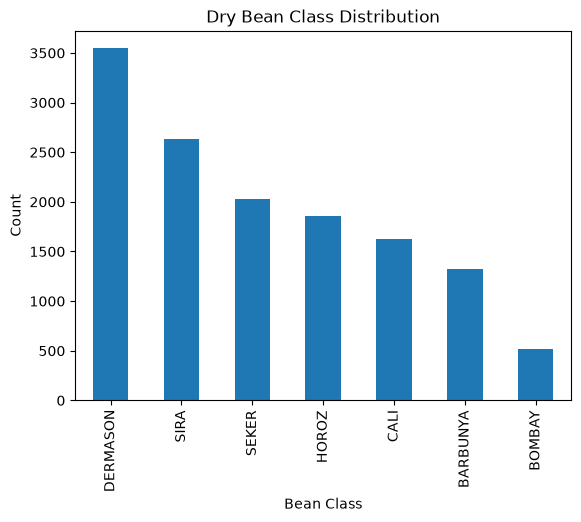

In [12]:
df["Class"].value_counts().plot(kind="bar")

plt.title("Dry Bean Class Distribution")
plt.xlabel("Bean Class")
plt.ylabel("Count")

plt.show()

In [13]:
# separate x and y
X = df.drop("Class", axis=1)
y = df["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (13543, 16)
y shape: (13543,)


In [15]:
# separate dataset for testing and training
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [16]:
# create adaboost model
from sklearn.ensemble import AdaBoostClassifier

adaboost_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

print("AdaBoost model created successfully!")

AdaBoost model created successfully!


In [17]:
adaboost_model.fit(X_train, y_train)

print("AdaBoost model trained successfully!")

AdaBoost model trained successfully!


In [18]:
y_pred = adaboost_model.predict(X_test)

print("Predictions completed successfully!")
print(y_pred[:10])

Predictions completed successfully!
['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER' 'DERMASON' 'DERMASON'
 'DERMASON' 'BARBUNYA' 'DERMASON']


In [19]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("AdaBoost Accuracy:", accuracy)
print("AdaBoost Accuracy:", accuracy * 100, "%")

AdaBoost Accuracy: 0.8154300479881875
AdaBoost Accuracy: 81.54300479881876 %


In [22]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(df["Class"])

print("Classes:", label_encoder.classes_)

Classes: ['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']


In [23]:
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

c:\Users\asusvivobook\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\asusvivobook\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\asusvivobook\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

              precision    recall  f1-score   support

    BARBUNYA       0.82      0.53      0.65       265
      BOMBAY       0.00      0.00      0.00       104
        CALI       0.57      0.94      0.71       326
    DERMASON       0.83      0.95      0.88       709
       HOROZ       0.97      0.90      0.93       372
       SEKER       0.92      0.90      0.91       406
        SIRA       0.87      0.74      0.80       527

    accuracy                           0.82      2709
   macro avg       0.71      0.71      0.70      2709
weighted avg       0.81      0.82      0.80      2709



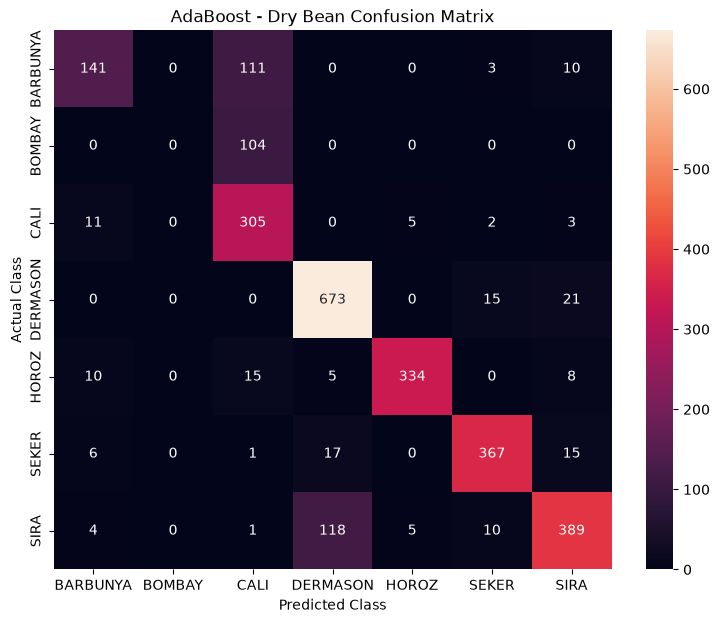

In [24]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("AdaBoost - Dry Bean Confusion Matrix")
plt.show()

In [25]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    adaboost_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross-validation scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())

Cross-validation scores: [0.78080295 0.83387171 0.88417167 0.81772035 0.87719298]
Mean CV Accuracy: 0.8387519329010111


In [26]:
import joblib

joblib.dump(adaboost_model, "dry_bean_adaboost_model.pkl")

print("AdaBoost model saved successfully!")

AdaBoost model saved successfully!


In [27]:
import joblib

joblib.dump(label_encoder, "dry_bean_label_encoder.pkl")

print("Label encoder saved successfully!")

Label encoder saved successfully!
